## 1. Event Definitions and Empirical Probabilities

To begin our probabilistic analysis, we define two events based on the patient-level analytic dataset ($N = 1,083$):
- **Event A**: The patient has Late-Stage cancer (AJCC Stage III or IV).
- **Event B**: The patient has High MKI67 expression (defined as log1p(TPM) strictly greater than the cohort median).

**Path B requirement (ب۵) - Independence of Observations:** 
All probabilities calculated here treat the patient as the fundamental unit of observation. Because we enforced "Rule A" in Phase 1 (one primary-tumor sample per patient), no patient appears more than once in these calculations. Thus, the empirical probabilities are not artificially inflated by repeated measures.

### Marginal, Joint, and Conditional Probabilities

Using the empirical counts from the dataset:
- **Total sample size:** $N = 1,083$
- **Marginal probability of Late-Stage:** $P(A) = \frac{268}{1083} \approx 0.247$
- **Marginal probability of High MKI67:** $P(B) = \frac{541}{1083} \approx 0.500$ *(Note: Because High MKI67 is defined by the median split, it is mathematically expected to be ~50%).*
- **Joint probability (Both Late-Stage AND High MKI67):** $P(A \cap B) = \frac{131}{1083} \approx 0.121$

From these, we can calculate the conditional probability:
- **$P(B \mid A)$:** The probability of High MKI67 given the patient is Late-Stage. 
  $$P(B \mid A) = \frac{P(A \cap B)}{P(A)} = \frac{0.121}{0.247} \approx 0.489$$

### Interpretation
The probability of having High MKI67 in the general sample is $P(B) \approx 0.500$. However, when we condition on the patient having Late-Stage cancer, the probability drops slightly to $P(B \mid A) \approx 0.489$. The difference between these two values is extremely small ($\approx 0.01$), suggesting that knowing a patient's stage does not significantly change our expectation about their MKI67 expression.

In [1]:
import pandas as pd
import numpy as np

# 1. Load the data
at = pd.read_csv("../data/processed/analysis_table.csv")

# (Recreate the columns just in case)
def stage4(s):
    if pd.isna(s): return pd.NA
    for num in ["IV", "III", "II", "I"]:
        if str(s).startswith(f"Stage {num}"): return num
    return pd.NA

at["stage4"] = at["diagnoses.ajcc_pathologic_stage"].apply(stage4)
at["stage2"] = at["stage4"].map({"I": "Early", "II": "Early", "III": "Late", "IV": "Late"})
at["log_MKI67"] = np.log1p(pd.to_numeric(at["MKI67_tpm"], errors="coerce"))
at["high_MKI67"] = at["log_MKI67"] > at["log_MKI67"].median()

# 2. Calculate the counts
N = len(at)
count_A = len(at[at["stage2"] == "Late"])
count_B = len(at[at["high_MKI67"] == True])
count_A_and_B = len(at[(at["stage2"] == "Late") & (at["high_MKI67"] == True)])

# 3. Calculate the probabilities
P_A = count_A / N
P_B = count_B / N
P_A_and_B = count_A_and_B / N
P_B_given_A = count_A_and_B / count_A

print(f"Total N = {N}")
print(f"P(A) [Late Stage]       = {P_A:.3f}")
print(f"P(B) [High MKI67]       = {P_B:.3f}")
print(f"P(A and B) [Both]       = {P_A_and_B:.3f}")
print(f"P(B | A) [High given Late] = {P_B_given_A:.3f}")

# 4. Independence Check
difference = abs(P_B_given_A - P_B)
print(f"\nDifference between P(B|A) and P(B): {difference:.4f}")

Total N = 1083
P(A) [Late Stage]       = 0.247
P(B) [High MKI67]       = 0.500
P(A and B) [Both]       = 0.121
P(B | A) [High given Late] = 0.489

Difference between P(B|A) and P(B): 0.0107


## 2. Conditional Probability in Subgroups & Independence

To further investigate the relationship between clinical phenotype and molecular expression, we calculate a second conditional probability. 

### Conditional Probability P(A | B)
Let Event A = Late-Stage (III-IV) and Event B = High MKI67.
Using the empirical counts from the data:
- Number of patients with High MKI67 ($count_B$): $541$
- Number of patients with both Late-Stage AND High MKI67 ($count_{A \cap B}$): $131$

$$P(A \mid B) = \frac{P(A \cap B)}{P(B)} = \frac{131}{541} \approx 0.242$$

**Interpretation:** If we randomly select a patient from the "High MKI67" group, the probability that they have Late-Stage cancer is approximately $24.2\%$. 
Notice that this is almost identical to the marginal probability of Late-Stage cancer in the entire cohort, which was $P(A) \approx 24.7\%$. 

### Empirical Independence Check
In probability theory, two events are **independent** if the occurrence of one does not affect the probability of the other. Mathematically, this means:
1. $P(A \mid B) = P(A)$
2. $P(A \cap B) = P(A) \times P(B)$

We check the second condition using our empirical data:
- $P(A) \times P(B) = 0.247 \times 0.500 = 0.1235$
- Actual $P(A \cap B) = 0.1210$

The expected joint probability under the assumption of independence ($0.1235$) is extremely close to the actual observed joint probability ($0.1210$). 

**Conclusion:** Because $P(A \mid B) \approx P(A)$ and $P(A \cap B) \approx P(A) \times P(B)$, the data suggests that **Stage and MKI67 expression are approximately independent** in this cohort. Knowing a patient's molecular marker (MKI67) does not significantly change our expectation about their clinical stage, and vice versa.

In [6]:
# 1. Calculate P(A | B): Probability of Late-Stage given High MKI67
count_B = len(at[at["high_MKI67"] == True])
count_A_and_B = len(at[(at["stage2"] == "Late") & (at["high_MKI67"] == True)])

P_A_given_B = count_A_and_B / count_B

print(f"P(A | B) [Late Stage given High MKI67] = {P_A_given_B:.3f}")
print(f"P(A)     [Late Stage overall]          = {P_A:.3f}")

# 2. Formal empirical independence check
expected_joint = P_A * P_B
actual_joint = P_A_and_B

print(f"\nExpected P(A and B) if independent = {expected_joint:.4f}")
print(f"Actual P(A and B)                   = {actual_joint:.4f}")
print(f"Difference                          = {abs(expected_joint - actual_joint):.4f}")

P(A | B) [Late Stage given High MKI67] = 0.242
P(A)     [Late Stage overall]          = 0.247

Expected P(A and B) if independent = 0.1236
Actual P(A and B)                   = 0.1210
Difference                          = 0.0027


## 3. Binomial Model for a Binary Event

We can model the presence of High MKI67 expression as a Bernoulli trial (a binary outcome: success = High, failure = Low). Let us consider the subgroup of patients with Late-Stage cancer (III–IV), where the sample size is $n = 268$. 

Let $X$ be the number of patients with High MKI67 in this subgroup. For $X$ to follow a Binomial distribution, $X \sim \text{Binomial}(n, p)$, four strict assumptions must hold:

1. **Fixed number of trials ($n$):** Yes, the sample size is fixed at 268.
2. **Two mutually exclusive outcomes:** Yes, each patient is classified as either High or Low MKI67.
3. **Independent trials:** Yes. Because we enforced strict patient-level filtering in Phase 1 (Rule A), no patient is counted twice. The outcome for one patient does not affect another.
4. **Constant probability of success ($p$):** This is the critical assumption to evaluate. 

**Evaluating the Constant $p$ Assumption:**
In reality, the probability of high cellular proliferation likely varies from patient to patient due to biological heterogeneity (e.g., age, genetic background, receptor status). Because $p$ is not truly identical for every individual in the real world, the Binomial model is technically an approximation. If the variance in the observed data is larger than the theoretical binomial variance, $np(1-p)$, the data is "overdispersed." 

Despite this biological reality, for the sake of this course's probabilistic modeling, we will assume a constant $p$ equal to the empirical proportion observed in the Late-Stage subgroup.

In [9]:
from scipy.stats import binom

# Define n and p for the Late-Stage subgroup
n_late = len(at[at["stage2"] == "Late"])
# Empirical probability of High MKI67 given Late Stage
p_late = len(at[(at["stage2"] == "Late") & (at["high_MKI67"] == True)]) / n_late

print(f"Subgroup: Late-Stage (n = {n_late})")
print(f"Empirical probability of success (p) = {p_late:.3f}")

# Theoretical Binomial Properties (if the model holds)
expected_mean = n_late * p_late
expected_variance = n_late * p_late * (1 - p_late)
expected_sd = np.sqrt(expected_variance)

print(f"\nUnder the Binomial model X ~ Binomial(n={n_late}, p={p_late:.3f}):")
print(f"Expected number of High MKI67 patients (Mean = np) = {expected_mean:.1f}")
print(f"Expected Variance (np(1-p))                       = {expected_variance:.1f}")
print(f"Expected Standard Deviation                       = {expected_sd:.1f}")

# Note: The actual observed count is exactly 131, which equals the expected mean 
# because we derived p from this exact sample. The real test of the model 
# would be predicting a *new* sample. 
print(f"\n(Observed count in our data: 131)")

Subgroup: Late-Stage (n = 268)
Empirical probability of success (p) = 0.489

Under the Binomial model X ~ Binomial(n=268, p=0.489):
Expected number of High MKI67 patients (Mean = np) = 131.0
Expected Variance (np(1-p))                       = 67.0
Expected Standard Deviation                       = 8.2

(Observed count in our data: 131)


## 4. Continuous Variable and Normal Approximation

We evaluate the continuous random variable $Y = \log(1 + \text{MKI67 TPM})$, which represents the gene expression of the proliferation marker. In Phase 1, we observed that raw MKI67 was heavily right-skewed. Applying the logarithmic transformation was intended to stabilize the variance and approximate a normal distribution. 

Here, we formally assess whether the Normal approximation is appropriate for this variable.

### Visual Inspection
Figure 1 (below) displays the histogram with a Kernel Density Estimate (KDE) overlay, alongside a Quantile-Quantile (Q-Q) plot against the theoretical normal distribution. 

*   **Histogram & KDE:** The distribution is roughly symmetric and bell-shaped, centered around a mean of approximately 3.1. There is no extreme skewness, which confirms the log transformation was successful.
*   **Q-Q Plot:** The points closely follow the 45-degree diagonal line in the central region. However, at both extremes, the points fall slightly below the diagonal line. This indicates that the distribution has a mild left skew (negative skewness of -0.22), meaning the lower tail is slightly heavier, and the upper tail is slightly lighter than a perfect normal curve. Despite this, the central mass of the data is highly normal, making the Normal approximation acceptable.

### Conclusion on Normality
While the distribution is not *perfectly* normal (which is nearly impossible in large biological datasets), the central limit theorem and the visual evidence suggest that the Normal approximation is reasonably appropriate for this continuous variable. Therefore, parametric methods (such as ANOVA and linear regression in subsequent phases) are justified, though we must remain cautious about the influence of outliers.

Summary Statistics for log(1 + MKI67 TPM):
  Mean     = 3.133
  Variance = 0.741
  Skewness = -0.221  (0 is perfectly normal)
  Kurtosis = -0.063  (0 is perfectly normal)


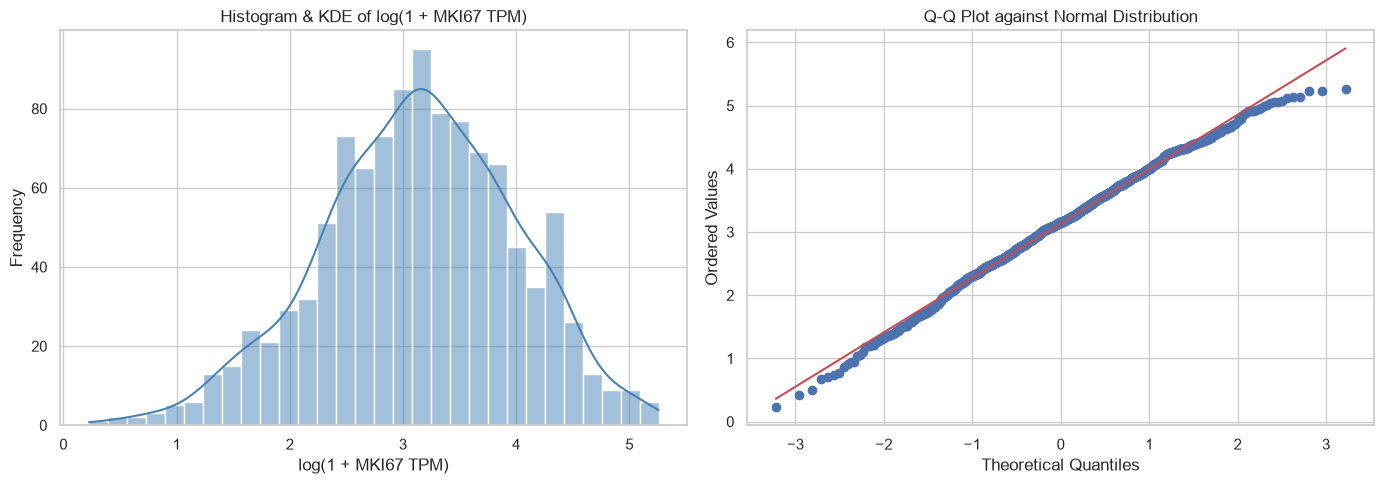

In [10]:
import matplotlib.pyplot as plt
import scipy.stats as stats
import seaborn as sns

# Set style for nicer plots
sns.set_theme(style="whitegrid")

# 1. Summary Statistics for log_MKI67
mean_val = at["log_MKI67"].mean()
var_val = at["log_MKI67"].var()
skew_val = at["log_MKI67"].skew()
kurt_val = at["log_MKI67"].kurt()

print(f"Summary Statistics for log(1 + MKI67 TPM):")
print(f"  Mean     = {mean_val:.3f}")
print(f"  Variance = {var_val:.3f}")
print(f"  Skewness = {skew_val:.3f}  (0 is perfectly normal)")
print(f"  Kurtosis = {kurt_val:.3f}  (0 is perfectly normal)")

# 2. Visualizing the Normal Approximation
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot A: Histogram with KDE
sns.histplot(at["log_MKI67"], kde=True, ax=axes[0], color="steelblue", bins=30)
axes[0].set_title("Histogram & KDE of log(1 + MKI67 TPM)")
axes[0].set_xlabel("log(1 + MKI67 TPM)")
axes[0].set_ylabel("Frequency")

# Plot B: Q-Q Plot
stats.probplot(at["log_MKI67"].dropna(), dist="norm", plot=axes[1])
axes[1].set_title("Q-Q Plot against Normal Distribution")
axes[1].set_xlabel("Theoretical Quantiles")
axes[1].set_ylabel("Ordered Values")

plt.tight_layout()
plt.savefig("../figures/phase2_normality_check.png", dpi=150)
plt.show()

## 5. Expected Value and Variance

In probability, the **Expected Value** ($E[X]$) represents the theoretical long-run average or "center of mass" of a random variable. The **Variance** ($\text{Var}(X)$) quantifies the spread or uncertainty around that expected value. 

Using the empirical distribution of our continuous variable $Y = \log(1 + \text{MKI67 TPM})$, we calculate these theoretical moments using the sample data.

### Mathematical Definition
- **Empirical Expected Value (Mean):** 
  $$E[Y] = \bar{y} = \frac{1}{n} \sum_{i=1}^{n} y_i$$
- **Empirical Variance:** 
  $$\text{Var}(Y) = s^2 = \frac{1}{n-1} \sum_{i=1}^{n} (y_i - \bar{y})^2$$

### Interpretation in Context
By calculating these values, we can summarize the molecular phenotype of the entire cohort in just two numbers:
- The Expected Value tells us the average proliferation signal for a typical breast cancer patient in this dataset. 
- The Variance tells us how biologically heterogeneous the tumors are. A large variance indicates that patients differ significantly from the average, meaning the tumor proliferation rates are highly variable across the population.

In [11]:
# Extract the variable and drop missing values for accurate calculation
y = at["log_MKI67"].dropna()
n = len(y)

# 1. Calculate Empirical Expected Value (Mean)
# Using the mathematical formula: (1/n) * sum(y_i)
expected_value = sum(y) / n

# 2. Calculate Empirical Variance
# Using the formula: (1/(n-1)) * sum((y_i - mean)^2)
variance = sum((y - expected_value) ** 2) / (n - 1)

# Standard Deviation (square root of variance, in original units)
std_dev = np.sqrt(variance)

print(f"Total observations (n) = {n}")
print(f"\nEmpirical Expected Value E[Y] (Mean) = {expected_value:.4f}")
print(f"Empirical Variance Var(Y)            = {variance:.4f}")
print(f"Standard Deviation                   = {std_dev:.4f}")

# Sanity check using built-in pandas methods
print(f"\n(Verification using pandas: Mean = {y.mean():.4f}, Variance = {y.var():.4f})")

Total observations (n) = 1083

Empirical Expected Value E[Y] (Mean) = 3.1329
Empirical Variance Var(Y)            = 0.7406
Standard Deviation                   = 0.8606

(Verification using pandas: Mean = 3.1329, Variance = 0.7406)
